# Can a return forecast improve on holding SPY?

Let's start with daily SPY prices, look at a few features, and try predicting the return we could actually trade. I would not expect much signal here. Beating a zero-return forecast is already a useful test; beating buy-and-hold after costs is a different question.

We use Convexity data for prices, Convexity math for fitting, and the SDK for orders and accounting. Install the notebook environment from the repository root with `python -m pip install -e '.[yahoo,neural,notebooks,calendars]'`. This downloads public Yahoo data; no broker login is needed.

In [1]:
from pathlib import Path
from decimal import Decimal
import hashlib
import importlib.metadata
import json

import convexity as cx
from convexity.data import history
from convexity.backtest import DataFrameHistoricalProvider
from convexity.math import learning, forecasting, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

pd.options.display.float_format = "{:,.4f}".format
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
torch.set_num_threads(1)

root = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
output = root / "out" / "predictive_trading"
output.mkdir(parents=True, exist_ok=True)

pd.Series({name: importlib.metadata.version(name)
           for name in ["convexity", "numpy", "pandas", "scikit-learn", "torch"]}, name="version")

convexity        0.1.0
numpy            2.4.6
pandas           3.0.5
scikit-learn     1.9.1
torch           2.14.0
Name: version, dtype: str

We keep the dates fixed so the experiment does not silently change every time we run it. Yahoo's unadjusted setting still adjusts for splits. We use those prices throughout and **exclude dividends** from both strategies; this is a price-return comparison, not a total-return benchmark.

The download and its metadata are saved under `out/predictive_trading`. The notebook fetches again when rerun, so revisions by Yahoo can change the results. The digest below identifies this particular download.

In [2]:
prices = history("SPY", provider="yahoo", start="2015-01-01", end="2026-01-01",
                 auto_adjust=False, actions=True)

assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert prices[["open", "high", "low", "close", "volume"]].notna().all().all()
assert (prices["stock_splits"] == 0).all(), "Review share accounting before using split dates."

csv = prices.to_csv()
(output / "prices.csv").write_text(csv)
provenance = {**prices.attrs, "sha256": hashlib.sha256(csv.encode()).hexdigest()}
(output / "prices.json").write_text(json.dumps(provenance, indent=2))
print(json.dumps(provenance, indent=2))
prices.head()

{
  "provider": "yahoo",
  "symbols": [
    "SPY"
  ],
  "interval": "1d",
  "start": "2015-01-01T00:00:00+00:00",
  "end": "2026-01-01T00:00:00+00:00",
  "end_exclusive": true,
  "fetched_at": "2026-10-14T20:09:14.968634+00:00",
  "sources": {
    "SPY": {
      "price_basis": "yahoo_split_adjusted",
      "auto_adjust": false,
      "prepost": false,
      "volume_unit": "provider_native",
      "timestamp_kind": "session_date"
    }
  },
  "sha256": "e5706074f228d2a25b73a011bacfa9a56865e0802d68f831b5c8c3e87e70654d"
}


,symbol,open,high,low,close,volume,adj_close,dividends,stock_splits,capital_gains
timestamp,,,,,,,,,,
2015-01-02 00:00:00+00:00,SPY,206.3800,206.8800,204.1800,205.4300,"121,465,900.0000",169.2675,0.0000,0.0000,0.0000
2015-01-05 00:00:00+00:00,SPY,204.1700,204.3700,201.3500,201.7200,"169,632,600.0000",166.2106,0.0000,0.0000,0.0000
2015-01-06 00:00:00+00:00,SPY,202.0900,202.7200,198.8600,199.8200,"209,151,400.0000",164.6451,0.0000,0.0000,0.0000
2015-01-07 00:00:00+00:00,SPY,201.4200,202.7200,200.8800,202.3100,"125,346,700.0000",166.6967,0.0000,0.0000,0.0000
2015-01-08 00:00:00+00:00,SPY,204.0100,206.1600,203.9900,205.9000,"147,217,800.0000",169.6548,0.0000,0.0000,0.0000


Before fitting anything, we separate training (2015–2021), model selection (2022–2023), and the final test (2024–2025). Feature plots below use training data only. The final test gets one pass, with no refitting or threshold search.

At the close of day *t* we can know that day's return, range, and volume. A market order then fills at the next open. Our target is therefore `open[t+2] / open[t+1] - 1`. The last two training decisions are excluded because their labels would not yet be known. This small timing detail matters more than adding another model.

In [3]:
close_return = prices["close"].pct_change(fill_method=None)
features = pd.DataFrame({
    "return_1d": close_return,
    "return_5d": prices["close"].pct_change(5, fill_method=None),
    "return_20d": prices["close"].pct_change(20, fill_method=None),
    "volatility_20d": close_return.rolling(20).std(),
    "intraday": prices["close"] / prices["open"] - 1,
    "range": (prices["high"] - prices["low"]) / prices["close"],
    "relative_volume": prices["volume"] / prices["volume"].rolling(20).mean() - 1,
}).dropna()

target = (prices["open"].shift(-2) / prices["open"].shift(-1) - 1).reindex(features.index)
label_end = pd.Series(prices.index, index=prices.index).shift(-2).reindex(features.index)
train_end = pd.Timestamp("2021-12-31", tz="UTC")
validation_end = pd.Timestamp("2023-12-31", tz="UTC")

train = (features.index <= train_end) & (label_end <= train_end)
validation = (features.index > train_end) & (label_end <= validation_end)
test = (features.index > validation_end) & target.notna()

pd.DataFrame({
    "decisions": [train.sum(), validation.sum(), test.sum()],
    "first": [features.index[mask][0].date() for mask in [train, validation, test]],
    "last": [features.index[mask][-1].date() for mask in [train, validation, test]],
}, index=["train", "validation", "test"])

,decisions,first,last
train,1741,2015-02-02,2021-12-29
validation,499,2022-01-03,2023-12-27
test,500,2024-01-02,2025-12-29


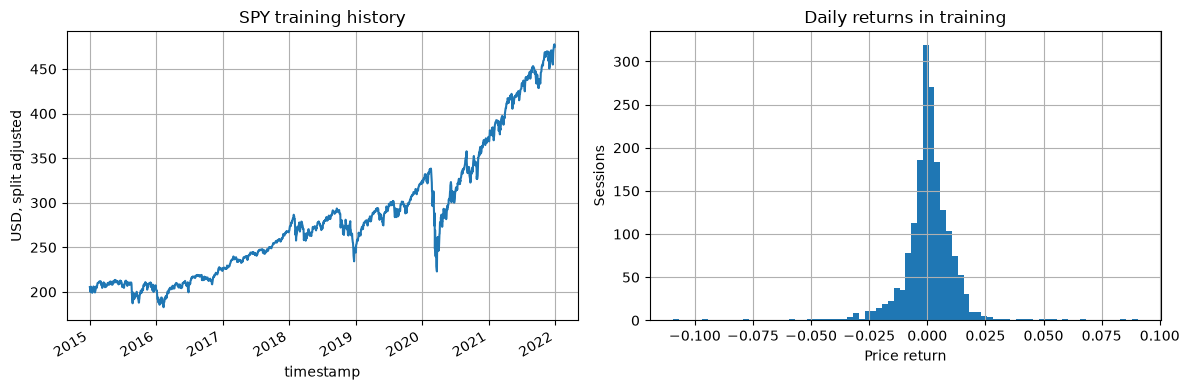

,mean,std,min,max
return_1d,0.0006,0.0112,-0.1094,0.0906
return_5d,0.0027,0.0225,-0.1797,0.1736
return_20d,0.0106,0.0435,-0.3139,0.2307
volatility_20d,0.0089,0.0068,0.0020,0.0589
intraday,0.0002,0.0077,-0.0566,0.0468
range,0.0106,0.0091,0.0012,0.0853
relative_volume,0.0071,0.3817,-0.6687,2.5573


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prices.loc[:train_end, "close"].plot(ax=axes[0], title="SPY training history", ylabel="USD, split adjusted")
close_return.loc[:train_end].hist(bins=80, ax=axes[1])
axes[1].set(title="Daily returns in training", xlabel="Price return", ylabel="Sessions")
plt.tight_layout()
plt.show()

features.loc[train].describe().T[["mean", "std", "min", "max"]]

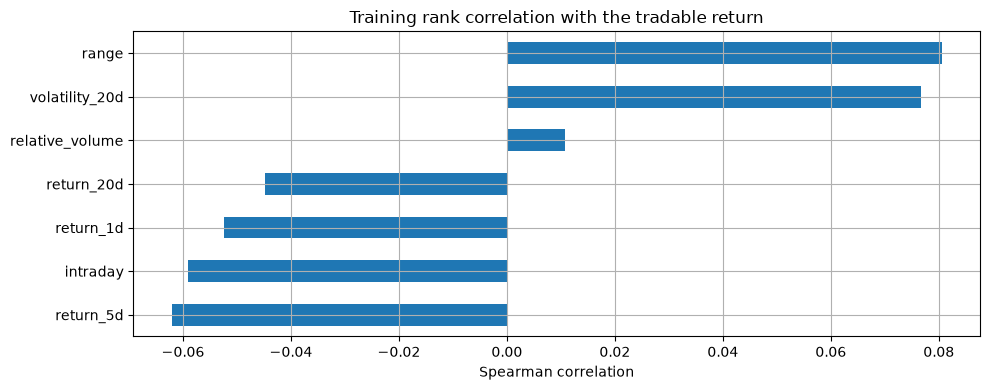

,return_1d,return_5d,return_20d,volatility_20d,intraday,range,relative_volume
2015,-0.1271,-0.0596,-0.1172,0.1748,-0.1471,0.1848,0.0831
2016,-0.0764,-0.0203,0.0053,0.1081,-0.1200,0.0764,-0.0352
2017,-0.0723,-0.1111,-0.0972,0.0467,0.0336,0.1868,0.1322
2018,0.0877,0.0382,-0.0149,-0.0240,0.0597,-0.0378,-0.0634
2019,-0.0619,-0.0821,-0.0440,0.1147,-0.0620,0.0603,0.0119
2020,-0.1135,-0.1360,-0.1081,0.0966,-0.1221,0.1014,0.0120
2021,-0.0293,-0.1483,-0.1575,0.1164,-0.0045,0.0833,0.0130


In [5]:
correlations = features.loc[train].corrwith(target.loc[train], method="spearman")
correlations.sort_values().plot.barh(title="Training rank correlation with the tradable return",
                                   xlabel="Spearman correlation")
plt.tight_layout()
plt.show()

by_year = features.loc[train].assign(target=target.loc[train]).groupby(features.index[train].year)
pd.DataFrame({year: frame.drop(columns="target").corrwith(frame["target"], method="spearman")
              for year, frame in by_year}).T

These correlations are descriptive. Seven features, several years, and several models give us plenty of chances to find something that looks promising by accident. We keep the features as specified and do not select them using the test period.

Let's fit a mean forecast, ridge regression, a shallow random forest, and a small neural network. Standardization belongs inside the fitted Convexity pipeline so it only sees training rows. Targets are in percentage points during fitting to keep the neural optimization scale sensible. The neural network has a fixed training budget; we show its convergence diagnostic instead of treating a finished loop as proof of convergence.

In [6]:
learners = {
    "Ridge": learning.Ridge(alpha=10.0),
    "Random forest": learning.RandomForest(n_estimators=150, max_depth=4,
                                           min_samples_leaf=40, seed=7),
    "Neural network": learning.NeuralRegressor(hidden_layers=(16, 8), seed=7,
                                              maxiter=1000, learning_rate=0.003,
                                              tolerance=1e-3, check_convergence=False),
}

fitted = {}
predictions = pd.DataFrame(index=features.index)
predictions["Zero"] = 0.0
predictions["Training mean"] = target.loc[train].mean()

for name, learner in learners.items():
    model = learning.Pipeline((transforms.Standardize(),), learner)
    fitted[name] = model.fit(features.loc[train].to_numpy(), target.loc[train].to_numpy() * 100)
    predictions[name] = fitted[name].predict_mean(features.to_numpy()) / 100

pd.DataFrame({name: {"iterations": model.diagnostics.iterations,
                    "converged": model.diagnostics.converged,
                    "message": model.diagnostics.message}
              for name, model in fitted.items()}).T

,iterations,converged,message
Ridge,None,True,
Random forest,None,True,
Neural network,1000,False,Adam iteration limit reached; gradient infinit...


The transformer gets a 20-session sequence of open-to-open returns and the same observed features. It predicts two steps ahead: the first forecast is the return ending at tomorrow's open, which we cannot capture with a new order; the second is the holding period we want.

Convexity handles the windows, training, and decoding. We reserve the last 126 training observations for early stopping. After fitting, `update(mode="incremental")` advances the context without changing weights or normalization. New prices can inform the next prediction, but future prices cannot inform today's prediction. Session numbers, rather than calendar days, define the forecast clock.

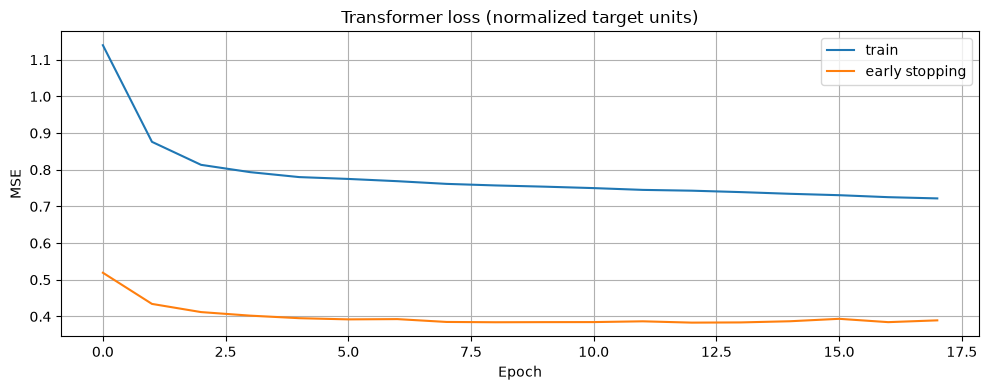

Trained for 18 epochs; evaluated 1003 subsequent sessions.


In [7]:
sequence_train = features.index <= train_end
scaler = transforms.Standardize().fit(features.loc[sequence_train].iloc[:-126].to_numpy())
observed_features = scaler.transform(features.to_numpy())
open_returns = prices["open"].pct_change(fill_method=None).reindex(features.index).to_numpy() * 100
n_train = int(sequence_train.sum())

transformer_spec = forecasting.TorchForecaster(
    architecture="transformer", context_length=20, max_horizon=2,
    hidden_size=16, head="point", epochs=30, batch_size=64,
    learning_rate=0.001, validation_size=126, patience=5, seed=7,
)
transformer = transformer_spec.fit(
    open_returns[:n_train],
    covariates=forecasting.Covariates(observed_past=observed_features[:n_train]),
)

losses = pd.DataFrame({"train": transformer.diagnostics.loss_history,
                       "early stopping": transformer.diagnostics.validation_history})
losses.plot(title="Transformer loss (normalized target units)", xlabel="Epoch", ylabel="MSE")
plt.tight_layout()
plt.show()

predictions["Transformer"] = np.nan
rolling_model = transformer
for row in range(n_train, len(features)):
    rolling_model = rolling_model.update(
        [open_returns[row]],
        covariates=forecasting.Covariates(observed_past=observed_features[row:row + 1]),
        mode="incremental",
    )
    predictions.loc[features.index[row], "Transformer"] = rolling_model.predict(2)[1, 0] / 100

print(f"Trained for {len(losses)} epochs; evaluated {len(features) - n_train} subsequent sessions.")

Compare validation RMSE against the unexciting baselines, then choose the best learned model for a trading demonstration. If a baseline wins, that is evidence against using these learned models. We also report directional accuracy and correlation; neither one tells us whether a strategy makes money. The transformer sees sequential information and has a different early-stopping policy, so this is an application comparison, not a controlled architecture benchmark.

In [8]:
def forecast_scores(mask):
    actual = target.loc[mask]
    rows = {}
    for name in predictions:
        predicted = predictions.loc[mask, name]
        assert predicted.notna().all()
        error = predicted - actual
        rows[name] = {
            "RMSE (bps)": np.sqrt(np.mean(error ** 2)) * 10_000,
            "MAE (bps)": np.mean(abs(error)) * 10_000,
            "direction accuracy": np.mean((predicted > 0) == (actual > 0)),
            "correlation": predicted.corr(actual) if predicted.std() > 1e-12 else np.nan,
        }
    return pd.DataFrame(rows).T

validation_scores = forecast_scores(validation).sort_values("RMSE (bps)")
learned_names = [*learners, "Transformer"]
selected = validation_scores.loc[learned_names, "RMSE (bps)"].idxmin()
print("Best overall validation forecast:", validation_scores.index[0])
print("Selected learned model:", selected)
validation_scores

Best overall validation forecast: Zero
Selected learned model: Ridge


,RMSE (bps),MAE (bps),direction accuracy,correlation
Zero,123.4501,92.8236,0.5030,NaN
Ridge,123.5368,92.9188,0.4970,0.0181
Training mean,123.5412,92.8960,0.4970,NaN
Random forest,124.8222,94.2564,0.4569,-0.0199
Transformer,125.3819,94.0004,0.4830,-0.0056
Neural network,143.3043,105.9689,0.4870,-0.0169


In [9]:
# Permutation importance on validation, in contiguous 20-session blocks.
# This measures reliance by this fitted ridge model, not economic causality.
rng = np.random.default_rng(7)
validation_x = features.loc[validation].to_numpy()
validation_y = target.loc[validation].to_numpy()
base_mse = np.mean((fitted["Ridge"].predict_mean(validation_x) / 100 - validation_y) ** 2)
importance = {}
blocks = np.array_split(np.arange(len(validation_x)), max(1, len(validation_x) // 20))

for column, name in enumerate(features.columns):
    changes = []
    for repeat in range(20):
        order = np.concatenate([blocks[i] for i in rng.permutation(len(blocks))])
        permuted = validation_x.copy()
        permuted[:, column] = validation_x[order, column]
        mse = np.mean((fitted["Ridge"].predict_mean(permuted) / 100 - validation_y) ** 2)
        changes.append((mse - base_mse) * 10_000 ** 2)
    importance[name] = {"mean MSE increase (bps²)": np.mean(changes),
                        "shuffle std": np.std(changes)}

pd.DataFrame(importance).T.sort_values("mean MSE increase (bps²)", ascending=False)

,mean MSE increase (bps²),shuffle std
return_5d,6.8512,6.7386
intraday,1.6131,6.4259
range,0.0578,0.1745
return_20d,-0.3136,1.6537
return_1d,-0.5567,1.6279
volatility_20d,-0.5913,3.2139
relative_volume,-0.6365,2.2421


Now open the test period. These results do not feed back into selection. A negative permutation importance or poor test score is useful evidence that the feature or model did not help this experiment.

In [10]:
test_scores = forecast_scores(test)
print("Model fixed before looking at test:", selected)
test_scores.sort_values("RMSE (bps)")

Model fixed before looking at test: Ridge


,RMSE (bps),MAE (bps),direction accuracy,correlation
Random forest,106.1452,68.2157,0.5540,0.1502
Transformer,106.5970,69.0769,0.5340,0.0997
Ridge,106.8879,68.2244,0.5700,0.2511
Training mean,107.0644,68.2592,0.5700,NaN
Zero,107.3399,68.9259,0.4300,NaN
Neural network,130.5022,80.2566,0.5020,0.0370


Let's turn the forecasts into actual orders. The rule is deliberately simple: hold SPY when the predicted daily return exceeds 5 bps, otherwise hold cash. The threshold is fixed in advance; it is not fitted to test returns. Entries use 95% of available cash to leave room for next-open gaps and fees. We do not rebalance an existing long position every day.

Each learned model and buy-and-hold get separate $100,000 accounts. Ridge was selected using validation; the other test accounts are shown for comparison and do not change that choice. Research publishes each completed daily bar at the next session open. The callback uses the forecast dated at that bar's close; orders can fill at the new session open under the simulator's zero-latency assumption. A live process would incur feed and order latency, so matching that opening price is optimistic. We charge 2 bps of spread, 1 bp of slippage, and $0.005/share with a $1 minimum. Idle cash earns zero. Remaining holdings are marked to the final close, with no forced liquidation.

In [11]:
provider = DataFrameHistoricalProvider(prices, price_basis="split_adjusted_price_return")

signals = predictions.loc[test, selected]
last_decision = signals.index[-1].date()

class ForecastStrategy(cx.Strategy):
    metadata = cx.StrategyMetadata("daily-return-forecast")
    contract = cx.StrategyContract(
        instruments=("SPY",),
        subscriptions=(cx.BarSubscription(("SPY",)), cx.EventSubscription(cx.Rejection)),
    )

    def __init__(self, forecasts):
        self.forecasts = {stamp.date(): value for stamp, value in forecasts.items()}

    def on_bar(self, event, context):
        # Daily observations arrive next session; key the signal by the observed close.
        day = event.bars["SPY"].end.date()
        if day not in self.forecasts or day > last_decision or context.pending("SPY"):
            return

        want_long = self.forecasts[day] > 0.0005
        position = context.position("SPY")
        if not want_long and position > 0:
            return cx.SubmitOrder.market("SPY", "SELL", position, time_in_force="GTC")

        if want_long and position == 0:
            account = context.account
            budget = min(account.cash_balances["USD"], account.available_funds) * Decimal("0.95")
            shares = int(budget / context.price("SPY"))
            if shares:
                return cx.SubmitOrder.market("SPY", "BUY", shares, time_in_force="GTC")

    def on_rejection(self, event, context):
        raise RuntimeError(event.reason)


async def replay(forecasts, execution):
    result = await cx.Research("2024-01-02", "2025-12-31").run_async(
        lambda: ForecastStrategy(forecasts),
        provider=provider, cache=None, initial_cash=100_000, execution=execution,
    )
    result.raise_for_failure()
    assert not result.open_orders
    return result

costs = cx.ExecutionModel.preset("standard")
results = {}
for name in learned_names:
    results[name] = await replay(predictions.loc[test, name], costs)
results["Buy and hold"] = await replay(pd.Series(1.0, index=signals.index), costs)
print({name: f"{len(result.fills)} fills" for name, result in results.items()})

{'Ridge': '159 fills', 'Random forest': '176 fills', 'Neural network': '250 fills', 'Transformer': '172 fills', 'Buy and hold': '1 fills'}


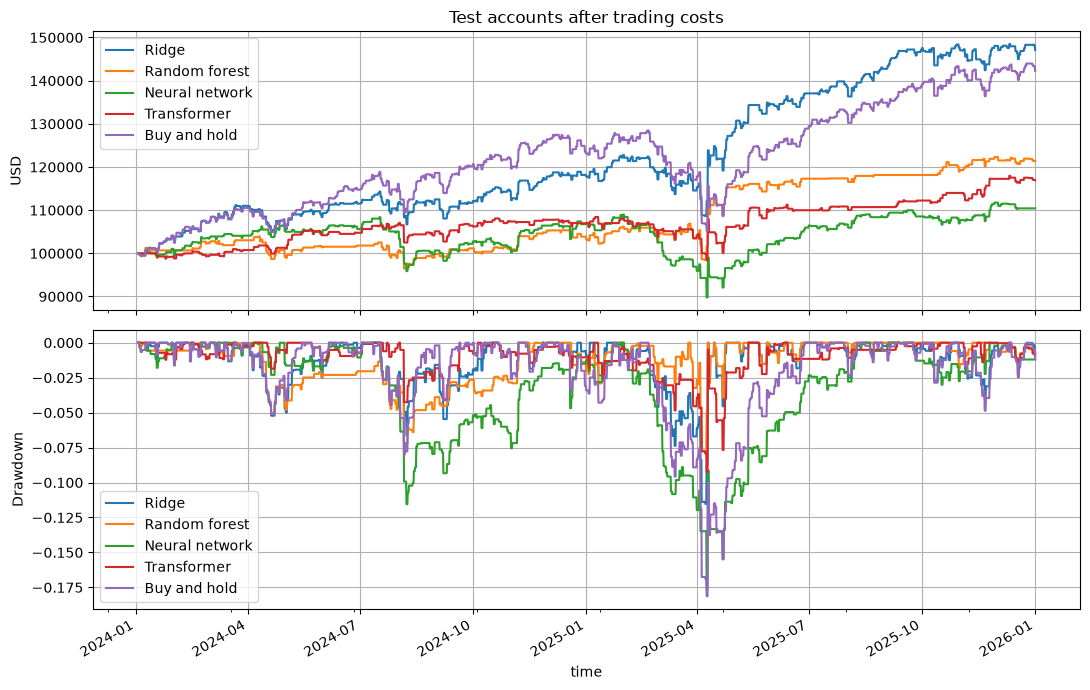

,total return,CAGR,volatility,Sharpe (rf=0),max drawdown,fills,fees ($),traded notional / initial equity
Ridge,0.4712,0.2133,0.1435,1.4213,-0.1153,159.0000,162.2600,185.4919
Random forest,0.2136,0.1018,0.1223,0.8547,-0.0790,176.0000,176.0300,179.5928
Neural network,0.1041,0.0509,0.1314,0.4432,-0.1762,250.0000,250.0000,246.9725
Transformer,0.1696,0.0816,0.1110,0.7631,-0.0925,172.0000,172.0000,174.3608
Buy and hold,0.4228,0.1932,0.1552,1.2177,-0.1813,1.0000,1.0000,0.9411


In [12]:
def equity_series(result):
    frame = pd.DataFrame(result.equity)
    frame["time"] = pd.to_datetime(frame["time"], utc=True)
    return frame.drop_duplicates("time", keep="last").set_index("time")["equity"].astype(float)


def performance(result):
    equity = equity_series(result)
    # One closing mark per session; keep the initial $100,000 for the first return.
    daily = equity.groupby(equity.index.date).last()
    returns = daily.pct_change(fill_method=None)
    returns.iloc[0] = daily.iloc[0] / 100_000 - 1
    years = (equity.index[-1] - equity.index[0]).total_seconds() / (365.25 * 86400)
    drawdown = equity / equity.cummax().clip(lower=100_000) - 1
    return {
        "total return": equity.iloc[-1] / 100_000 - 1,
        "CAGR": (equity.iloc[-1] / 100_000) ** (1 / years) - 1,
        "volatility": returns.std() * np.sqrt(252),
        "Sharpe (rf=0)": returns.mean() / returns.std() * np.sqrt(252) if returns.std() else np.nan,
        "max drawdown": drawdown.min(),
        "fills": len(result.fills),
        "fees ($)": sum(float(fill.fee) for fill in result.fills),
        "traded notional / initial equity": sum(float(fill.price * fill.quantity) for fill in result.fills) / 100_000,
    }

curves = pd.DataFrame({name: equity_series(result) for name, result in results.items()})
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
curves.plot(ax=axes[0], title="Test accounts after trading costs", ylabel="USD")
(curves / curves.cummax().clip(lower=100_000) - 1).plot(ax=axes[1], ylabel="Drawdown")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({name: performance(result) for name, result in results.items()}).T
summary

The account comparison also needs some uncertainty. Resampling paired 20-session blocks preserves some short-range dependence and keeps the two strategies on the same market path. This interval is for the annualized mean daily return difference, not the difference in CAGR. It does not account for model selection, research choices, or a different future market regime.

In [13]:
daily_curves = curves.groupby(curves.index.date).last()
daily_returns = daily_curves.pct_change(fill_method=None).dropna()
excess = (daily_returns[selected] - daily_returns["Buy and hold"]).to_numpy()

rng = np.random.default_rng(42)
block_length = 20
starts = rng.integers(0, len(excess), size=(2000, int(np.ceil(len(excess) / block_length))))
indices = (starts[..., None] + np.arange(block_length)) % len(excess)
resampled = excess[indices.reshape(2000, -1)[:, :len(excess)]]
interval = np.quantile(resampled.mean(axis=1) * 252, [0.025, 0.975])
print(f"Annualized mean daily excess return: {excess.mean() * 252:.1%}")
print(f"95% paired block-bootstrap interval: [{interval[0]:.1%}, {interval[1]:.1%}]")

Annualized mean daily excess return: 1.5%
95% paired block-bootstrap interval: [-9.3%, 16.8%]


The cost assumptions deserve their own check. We repeat both accounts with no trading costs and with a wider spread/slippage, keeping the signals fixed. The wider-cost case changes only costs, not execution timing. This is a sensitivity analysis, not another model-selection round.

In [14]:
wide_costs = cx.ExecutionModel(spread_bps=6, slippage_bps=3,
                               commission_per_share="0.005", minimum_commission=1,
                               volume_participation="0.1")
sensitivity = []
for label, execution in [("zero", cx.ExecutionModel()), ("standard", costs), ("wide", wide_costs)]:
    for name, forecasts in [(selected, signals), ("Buy and hold", pd.Series(1.0, index=signals.index))]:
        result = results[name] if label == "standard" else await replay(forecasts, execution)
        sensitivity.append({"costs": label, "strategy": name, **performance(result)})

pd.DataFrame(sensitivity).set_index(["costs", "strategy"])[["total return", "max drawdown", "fees ($)"]]

total return  max drawdown  fees ($)
costs    strategy                                          
zero     Ridge               0.5183       -0.1139    0.0000
         Buy and hold        0.4230       -0.1812    0.0000
standard Ridge               0.4712       -0.1153  162.2600
         Buy and hold        0.4228       -0.1813    1.0000
wide     Ridge               0.3845       -0.1181  159.6500
         Buy and hold        0.4224       -0.1813    1.0000

In [15]:
predictions.loc[validation | test].assign(realized=target).to_csv(output / "predictions.csv")
summary.to_csv(output / "performance.csv")
for name, result in results.items():
    result.export(output / name.lower().replace(" ", "_"))

strategy_return = summary.loc[selected, "total return"]
benchmark_return = summary.loc["Buy and hold", "total return"]
print(f"Validation selected {selected}. Test return: {strategy_return:.1%}; buy and hold: {benchmark_return:.1%}.")
print(f"Difference: {strategy_return - benchmark_return:+.1%}. Long signal on {(signals > 0.0005).mean():.1%} of decisions.")
print(f"Forecast RMSE: {test_scores.loc[selected, 'RMSE (bps)']:.2f} bps; zero forecast: {test_scores.loc['Zero', 'RMSE (bps)']:.2f} bps.")

Validation selected Ridge. Test return: 47.1%; buy and hold: 42.3%.
Difference: +4.8%. Long signal on 74.2% of decisions.
Forecast RMSE: 106.89 bps; zero forecast: 107.34 bps.


In the stored run, ridge finished ahead: 47.1% versus 42.3% for buy-and-hold, after the stated costs. But the paired interval for annualized mean excess return was roughly −9% to +17%, and the zero forecast won on validation. I would not call this an established edge.

The random forest had the lowest test forecast RMSE but its trading account returned only 21.4%. Better forecast error did not translate into a better long-or-cash strategy. The neural network and transformer also failed to justify their extra complexity here. Lower drawdown partly reflects their time in cash.

This is one ETF, one fixed split, one seed, and a small set of hand-picked features. A stronger claim needs further rolling periods and untouched markets, and a total-return benchmark. The daily simulator cannot establish intraday liquidity, market impact, or live feed reliability. Those are remaining research questions, not reasons to tune the test period until the plots look better.